In [2]:
#Importamos las librerías que vamos a utilizar
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Escribimos una función para limpiar los nombres de las columnas, elimina [] y espacios y los reemplaza con _
def limpiar_nombres_columnas(df):
    df = df.copy()
    df.columns = [
        re.sub(r"[\[\]<>]", "", str(col))
        .strip()
        .replace(" ", "_")
        for col in df.columns
    ]
    return df

In [3]:
ruta = r"Material/Datasets/ai4i2020.csv"
df = pd.read_csv(ruta)

# Aplicamos la limpieza
df = limpiar_nombres_columnas(df)

In [4]:
# Mostramos la cantidad de filas y columnas del DataFrame
print("El DataFrame tiene", df.shape[0], "filas y", df.shape[1] ,"columnas")


El DataFrame tiene 10000 filas y 14 columnas


In [5]:
# Mostramos las primeras filas del DataFrame
df.head()


,UDI,Product_ID,Type,Air_temperature_K,Process_temperature_K,Rotational_speed_rpm,Torque_Nm,Tool_wear_min,Machine_failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [6]:
# Eliminamos las variables UDI y Product_ID
df.drop(columns=['UDI', 'Product_ID'], inplace=True)

In [7]:
# Creamos un nuevo DataFrame para juntar informaciones
info_df = pd.DataFrame({
    'Tipo de Dato': df.dtypes,
    'Valores Nulos': df.isnull().sum(),
})

# Asignamos un nombre a la primera columna del DataFrame
info_df = info_df.reset_index().rename(columns={'index': 'Variables'})

info_df


,Variables,Tipo de Dato,Valores Nulos
0,Type,object,0
1,Air_temperature_K,float64,0
2,Process_temperature_K,float64,0
3,Rotational_speed_rpm,int64,0
4,Torque_Nm,float64,0
5,Tool_wear_min,int64,0
6,Machine_failure,int64,0
7,TWF,int64,0
8,HDF,int64,0
9,PWF,int64,0


In [8]:
# Generamos las estadísticas descriptivas del DataFrame
df.describe()


,Air_temperature_K,Process_temperature_K,Rotational_speed_rpm,Torque_Nm,Tool_wear_min,Machine_failure,TWF,HDF,PWF,OSF,RNF
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


## 1.2. Diagnóstico del Balance de Clases ##



In [9]:
# Vamos a ver la cantidad de fallas que hay en el dataset
conteo_fallas = df['Machine_failure'].value_counts()

# Calculamos el porcentaje de fallas en el dataset
porcentaje_fallas = df['Machine_failure'].value_counts(normalize=True) * 100

# Resumen 
resumen_fallas = pd.DataFrame({
    'Cantidad de fallas' : conteo_fallas,
    'Porcentaje (%)' : porcentaje_fallas.round(4)
})

resumen_fallas.index.name = None

resumen_fallas


,Cantidad de fallas,Porcentaje (%)
0,9661,96.61
1,339,3.39


A partir del análisis cuantitativo de la variable objetivo `Machine_failure`, se extraen las siguientes conclusiones analíticas fundamentales para el desarrollo del modelo:

* **Predominancia de la Clase Mayoritaria:** El **96.61%** de los registros históricos corresponden a un estado operativo normal (Clase `0`), sumando un total de **9,661 observaciones**.
* **Presencia de la Clase Minoritaria (Target):** Se registraron únicamente **339 eventos de falla mecánica** (Clase `1`), lo que equivale al **3.39%** del conjunto de datos total.


## 1.3 Análisis Desagregado de Tipos de Falla ##



### 1.3.1 Distribución de tipos de falla ###

In [10]:
# Creamos una lista con las columnas de fallas específicas
columnas_fallas = ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']

# Sumamos los valores de cada columna
conteo_fallas_especificas = df[columnas_fallas].sum()

# Creamos un DataFrame y lo ordenamos de mayor a menor
tabla_fallas_especificas = pd.DataFrame({
    'Total de Eventos': conteo_fallas_especificas,
}).sort_values(by='Total de Eventos', ascending=False)

# Quitamos el nombre del índice para que quede más limpio
tabla_fallas_especificas.index.name = None

# Calculamos la suma total de eventos y lo agregamos a la tabla
tabla_fallas_especificas.loc['Total'] = tabla_fallas_especificas.sum()

tabla_fallas_especificas


,Total de Eventos
HDF,115
OSF,98
PWF,95
TWF,46
RNF,19
Total,373


Para entender la naturaleza del desbalance, se aislaron y contabilizaron de forma independiente los modos de falla registrados por los sensores:

* **HDF (Heat Dissipation Failure - 115 eventos):** Es la causa principal de avería. Indica problemas críticos de disipación térmica y sobrecalentamiento en la operación.
* **OSF (Overstrain Failure - 98 eventos):** El segundo factor de riesgo, asociado a tensiones mecánicas excesivas o sobreesfuerzos estructurales.
* **PWF (Power Failure - 95 eventos):** Fallos directamente relacionados con fluctuaciones o pérdidas en el suministro de potencia eléctrica.
* **TWF (Tool Wear Failure - 45 eventos):** Desgaste acumulado de la herramienta de corte que alcanza su límite seguro.
* **RNF (Random Failure - 18 eventos):** Eventos de fallo aleatorios no correlacionados directamente con los sensores principales.
<br>
<br>
> 💡 **Nota de Consistencia de Datos:** Si sumamos todos estos eventos individuales obtenemos 373 fallas, lo cual supera las 339 fallas registradas identificadas con 'Machine_failure = 1'. Este hallazgo es clave para nuestro análisis EDA: **existen ciclos de operación específicos donde la máquina sufrió múltiples modos de falla simultáneos** durante el mecanizado de una pieza.




### 1.3.2 Análisis de fallas simultáneas ###


In [11]:
fallas_multiples = df[df[columnas_fallas].sum(axis=1) >= 2].copy()

# Agregamos una columna que nos indique que fallas ocurrieron a la misma vez
fallas_multiples['Fallas simultáneas'] = fallas_multiples[columnas_fallas].apply(
    lambda fila: ', '.join([col for col in columnas_fallas if fila[col] == 1]),
    axis = 1
)

tabla_fallas_multiples = fallas_multiples [['Machine_failure', 'Fallas simultáneas']].reset_index()
tabla_fallas_multiples.columns = ['ID ciclo', 'Alarma general', 'Modos de fallas detectados']

tabla_render = tabla_fallas_multiples.set_index('ID ciclo')

# Mostramos la cantidad total abajo
print(f"Total de registros con fallas simultáneas: {len(tabla_fallas_multiples)}")



Total de registros con fallas simultáneas: 24


### Verificación de consistencia entre fallas generales y específicas

El dataset AI4I 2020 contiene una variable objetivo general (`Machine_failure`) y cinco indicadores de tipos de falla (`TWF`, `HDF`, `PWF`, `OSF` y `RNF`).

La suma de las etiquetas específicas no necesariamente coincide con la cantidad de registros que presentan una falla general, debido a que un mismo registro puede contener más de un tipo de falla.

Para comprender esta diferencia, analizaremos cuatro situaciones:

1. **Fallas simultáneas:** registros con dos o más tipos de falla activos.
2. **Fallas específicas sin falla general:** registros donde `Machine_failure = 0`, pero al menos una etiqueta específica vale 1.
3. **Fallas generales sin tipo identificado:** registros donde `Machine_failure = 1`, pero todas las etiquetas específicas valen 0.
4. **Fallas aleatorias (`RNF`):** registros con esta etiqueta activa, diferenciando su relación con la falla general.

El objetivo es verificar la consistencia de las etiquetas y comprender las particularidades del dataset, sin atribuir causas físicas que no puedan demostrarse a partir de los datos disponibles.

In [12]:
# Filtramos el DataFrame, cuando Machine_failure = 0 y alguna columna de fallo es = 1
dataset_filtrado_1 = df[(df['Machine_failure'] == 0) & (df[columnas_fallas].sum(axis=1) == 1)]
dataset_filtrado_1_1 = df[(df['Machine_failure'] == 1) & (df['RNF'] == 1)]

display(dataset_filtrado_1)
display(dataset_filtrado_1_1)

# Realizamos el conteo de filas
print('Hay un total de:', len(dataset_filtrado_1)+len(dataset_filtrado_1_1), 'registros donde Machine failura = 0 y RNF = 1')


,Type,Air_temperature_K,Process_temperature_K,Rotational_speed_rpm,Torque_Nm,Tool_wear_min,Machine_failure,TWF,HDF,PWF,OSF,RNF
1221,M,297.0,308.3,1399,46.4,132,0,0,0,0,0,1
1302,L,298.6,309.8,1505,45.7,144,0,0,0,0,0,1
1748,H,298.4,307.7,1626,31.1,166,0,0,0,0,0,1
2072,L,299.6,309.5,1570,35.5,189,0,0,0,0,0,1
2559,L,299.3,309.0,1447,50.4,140,0,0,0,0,0,1
3065,M,300.1,309.2,1687,27.7,95,0,0,0,0,0,1
3452,H,301.6,310.5,1602,32.3,2,0,0,0,0,0,1
5471,L,302.7,312.3,1346,61.2,170,0,0,0,0,0,1
5489,L,302.6,312.1,1499,35.0,215,0,0,0,0,0,1
5495,H,302.9,312.5,1357,55.0,12,0,0,0,0,0,1


,Type,Air_temperature_K,Process_temperature_K,Rotational_speed_rpm,Torque_Nm,Tool_wear_min,Machine_failure,TWF,HDF,PWF,OSF,RNF
3611,L,301.7,310.9,1405,46.4,207,1,1,0,0,0,1


Hay un total de: 19 registros donde Machine failura = 0 y RNF = 1


In [13]:
dataset_filtrado_2 = df[(df['Machine_failure'] == 1) & (df[columnas_fallas].sum(axis=1) == 0)]
display(dataset_filtrado_2)

# Realizamos el conteo de filas
print('Hay un total de:', len(dataset_filtrado_2), 'registros donde Machine failura = 1 y [TWF, HDF, PWF, OSF] = 0')


,Type,Air_temperature_K,Process_temperature_K,Rotational_speed_rpm,Torque_Nm,Tool_wear_min,Machine_failure,TWF,HDF,PWF,OSF,RNF
1437,H,298.8,309.9,1439,45.2,40,1,0,0,0,0,0
2749,M,299.7,309.2,1685,28.9,179,1,0,0,0,0,0
4044,M,301.9,310.9,1419,47.7,20,1,0,0,0,0,0
4684,M,303.6,311.8,1421,44.8,101,1,0,0,0,0,0
5536,M,302.3,311.8,1363,54.0,119,1,0,0,0,0,0
5941,L,300.6,310.7,1438,48.5,78,1,0,0,0,0,0
6478,L,300.5,309.8,1663,29.1,145,1,0,0,0,0,0
8506,L,298.4,309.6,1710,27.3,163,1,0,0,0,0,0
9015,L,297.2,308.1,1431,49.7,210,1,0,0,0,0,0


Hay un total de: 9 registros donde Machine failura = 1 y [TWF, HDF, PWF, OSF] = 0


### 1.3.3 Consistencia entre etiquetas ###

In [14]:
# Columnas que identifican los tipos de falla
columnas_fallas = ["TWF", "HDF", "PWF", "OSF", "RNF"]

# Cantidad de etiquetas específicas activas por registro
cantidad_tipos = df[columnas_fallas].sum(axis=1)

# 1. Registros con múltiples tipos de falla
fallas_simultaneas = df[cantidad_tipos >= 2]

# 2. Falla específica sin falla general
especifica_sin_general = df[
    (df["Machine_failure"] == 0) &
    (cantidad_tipos >= 1)
]

# 3. Falla general sin tipo específico
general_sin_especifica = df[
    (df["Machine_failure"] == 1) &
    (cantidad_tipos == 0)
]

# 4. Registros con falla aleatoria
fallas_random = df[df["RNF"] == 1]

# Resumen de resultados
resumen_fallas = pd.DataFrame({
    "Indicador": [
        "Registros con falla general",
        "Total de etiquetas específicas activas",
        "Registros con fallas simultáneas",
        "Falla específica sin falla general",
        "Falla general sin tipo específico",
        "Registros con RNF",
        "RNF sin falla general",
        "RNF con falla general"
    ],
    "Cantidad": [
        int(df["Machine_failure"].sum()),
        int(cantidad_tipos.sum()),
        len(fallas_simultaneas),
        len(especifica_sin_general),
        len(general_sin_especifica),
        len(fallas_random),
        len(fallas_random[
            fallas_random["Machine_failure"] == 0
        ]),
        len(fallas_random[
            fallas_random["Machine_failure"] == 1
        ])
    ]
})

display(resumen_fallas)

# Comprobación matemática de la diferencia
diferencia_real = (
    cantidad_tipos.sum() - df["Machine_failure"].sum()
)

diferencia_explicada = (
    (cantidad_tipos - 1).clip(lower=0).sum()
    + len(especifica_sin_general)
    - len(general_sin_especifica)
)

print("Diferencia real:", diferencia_real)
print("Diferencia explicada:", diferencia_explicada)

assert diferencia_real == diferencia_explicada, (
    "Los conteos no son consistentes"
)

,Indicador,Cantidad
0,Registros con falla general,339
1,Total de etiquetas específicas activas,373
2,Registros con fallas simultáneas,24
3,Falla específica sin falla general,18
4,Falla general sin tipo específico,9
5,Registros con RNF,19
6,RNF sin falla general,18
7,RNF con falla general,1


Diferencia real: 34
Diferencia explicada: 34


### Análisis de Discrepancias en los Registros de Falla

Al comparar la variable objetivo principal (`Machine_failure`) con las columnas de fallas específicas (`TWF`, `HDF`, `PWF`, `OSF`, `RNF`), se observa una inconsistencia numérica. Mientras que el sistema registra **339** paradas de máquina generales, la suma individual de las alarmas específicas asciende a **373**. 

Esta diferencia neta de **34 eventos** (373 - 339) es el resultado de tres comportamientos operativos y de recolección de datos dentro del dataset:

#### 1. Fallas Simultáneas (+24 en fallas específicas)
Se identificaron **24 ciclos de trabajo** donde la máquina experimentó dos modos de falla al mismo tiempo (por ejemplo, un pico de sobreesfuerzo mecánico que deriva en un problema de disipación de calor).

#### 2. Fallas Aleatorias u Ocultas (+19 en fallas específicas)
Existen **19 registros** clasificados como fallas aleatorias (`RNF` = 1) donde la alarma general de la máquina nunca se activó (`Machine_failure` = 0).
* **Impacto en los datos:** Al estar presentes en las causas específicas pero no sumar al conteo general, generan un excedente de **+19**.
* **Significado analítico:** La documentación técnica del dataset define las `RNF` como simulaciones de eventos ajenos al proceso de mecanizado (ej. caídas de tensión eléctrica o errores de hardware). Representan ruido estocástico que no responde a la termodinámica ni a la cinemática del equipo.

#### 3. Fallas Fantasma (-9 en fallas específicas)
Se detectaron **9 casos** donde la máquina registró una parada general (`Machine_failure` = 1), pero todos los sensores de fallas específicas (incluyendo las aleatorias) marcaron 0.
* **Impacto en los datos:** Suman 9 eventos al recuento general sin aportar ninguna causa específica, lo que resta **-9** a la diferencia neta.
* **Significado analítico:** En un entorno industrial, esto equivale a una falsa alarma del panel de control o a una parada por un factor no medido en la telemetría actual. 

#### Balance Final de la Discrepancia
La diferencia matemática queda perfectamente cerrada al cruzar estos tres fenómenos en el dataset:

* **+ 24** (Fallas múltiples que duplican la causa específica)
* **+ 19** (Fallas aleatorias no registradas en la alarma general)
* **- 9** (Falsas alarmas sin causa registrada)
* **= 34** (Diferencia exacta entre las 373 causas específicas y las 339 paradas generales).


### Conclusiones del análisis de consistencia

El análisis permitió identificar 339 registros con falla general y 373 activaciones de etiquetas específicas. La diferencia de 34 activaciones se explica mediante los registros con múltiples tipos de falla y las discrepancias entre la etiqueta general y las etiquetas específicas.

Se identificaron 24 registros con fallas simultáneas, 18 casos con alguna falla específica activa pero sin falla general, y 9 casos con falla general sin un tipo específico identificado.

Un hallazgo relevante es el comportamiento de `RNF` (*Random Failure*): de los 19 registros con esta etiqueta activa, 18 presentan `Machine_failure = 0` y solamente uno presenta `Machine_failure = 1`.

Estos resultados muestran que las etiquetas específicas y la etiqueta general no son completamente equivalentes. Por lo tanto, no deben utilizarse indistintamente ni interpretarse sus discrepancias como errores de sensores o falsas alarmas reales sin evidencia adicional.

**Implicancias para el modelado:** se mantendrá `Machine_failure` como variable objetivo de clasificación binaria. Los indicadores `TWF`, `HDF`, `PWF`, `OSF` y `RNF` serán excluidos de las variables predictoras para evitar fuga de información.

Además, se documentarán las inconsistencias entre etiquetas como una limitación del conjunto de datos, especialmente al interpretar los resultados y evaluar su posible aplicación industrial.

## 1.4 Análisis estadístico de variables físicas ##

1. Análisis descriptivo univariado. Seleccionamos las variables numéricas `Air Temperature [K]`, `Process Temperature [K]`, `Rotational Speed [rpm]`, `Torque_Nm`, `Tool Wear [min]` para analizar asimetría y curtosis


In [15]:
# Primero identificamos los tipos de cada variable
df.dtypes

Type                      object
Air_temperature_K        float64
Process_temperature_K    float64
Rotational_speed_rpm       int64
Torque_Nm                float64
Tool_wear_min              int64
Machine_failure            int64
TWF                        int64
HDF                        int64
PWF                        int64
OSF                        int64
RNF                        int64
dtype: object

In [16]:
# Nos quedamos únicamente con las variables físicas
variables_fisicas = [
    'Air_temperature_K', 
    'Process_temperature_K', 
    'Rotational_speed_rpm', 
    'Torque_Nm', 
    'Tool_wear_min'
]
df[variables_fisicas]

,Air_temperature_K,Process_temperature_K,Rotational_speed_rpm,Torque_Nm,Tool_wear_min
0,298.1,308.6,1551,42.8,0
1,298.2,308.7,1408,46.3,3
2,298.1,308.5,1498,49.4,5
3,298.2,308.6,1433,39.5,7
4,298.2,308.7,1408,40.0,9
...,...,...,...,...,...
9995,298.8,308.4,1604,29.5,14
9996,298.9,308.4,1632,31.8,17
9997,299.0,308.6,1645,33.4,22
9998,299.0,308.7,1408,48.5,25


Vemos en la siguiente celda el resultado de calcular la asimetría y la curtosis. La única variable que muestra una asimetría más marcada es `Rotational Speed [rpm]`. Los valores altos de curtosis indican una distribución estirada, con colas muy anchas y valores extremos.


In [17]:
print(f"Asimetría de las variables: \n{df[variables_fisicas].skew()}\n")
print(f"Curtosis de las variables: \n{df[variables_fisicas].kurtosis()}")

Asimetría de las variables: 
Air_temperature_K        0.114274
Process_temperature_K    0.015027
Rotational_speed_rpm     1.993171
Torque_Nm               -0.009517
Tool_wear_min            0.027292
dtype: float64

Curtosis de las variables: 
Air_temperature_K       -0.835962
Process_temperature_K   -0.499734
Rotational_speed_rpm     7.392945
Torque_Nm               -0.013241
Tool_wear_min           -1.166737
dtype: float64


2. Distribución de las variables


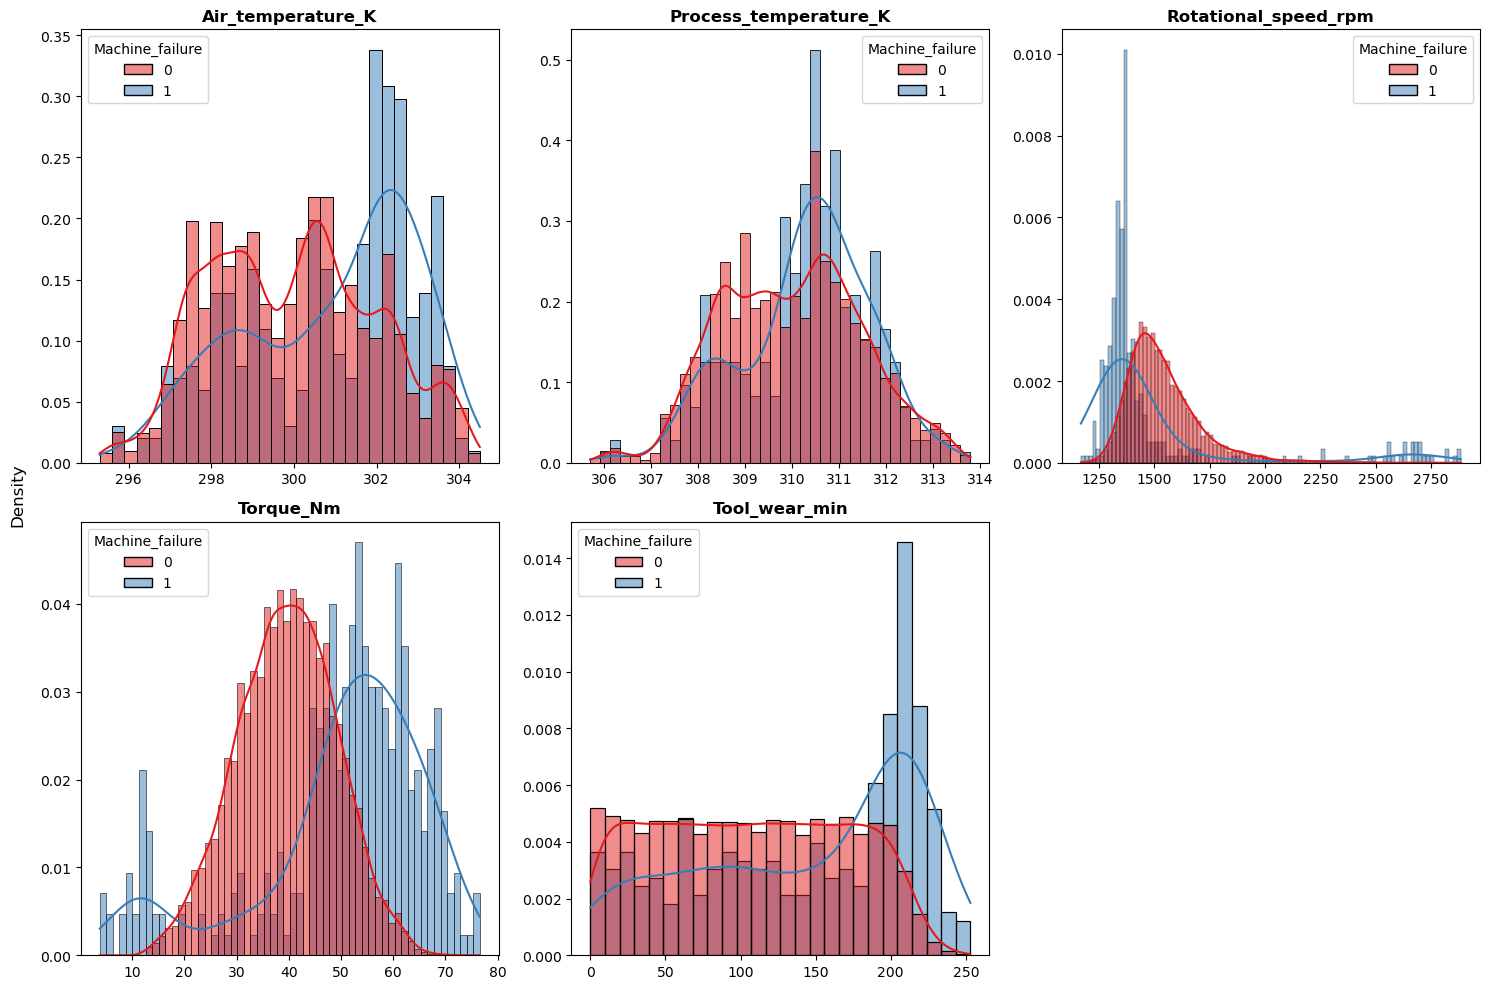

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(variables_fisicas):
    sns.histplot(
        data=df, 
        x=col, 
        hue='Machine_failure', 
        kde=True, 
        stat='density',
        common_norm=False,
        palette='Set1',
        alpha=0.5,
        ax=axes[i]
    )
    
    axes[i].set_title(col, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('')

axes[5].axis('off')
fig.supylabel('Density', x=0.01)

plt.tight_layout()
plt.show()

3. Boxplot de las variables


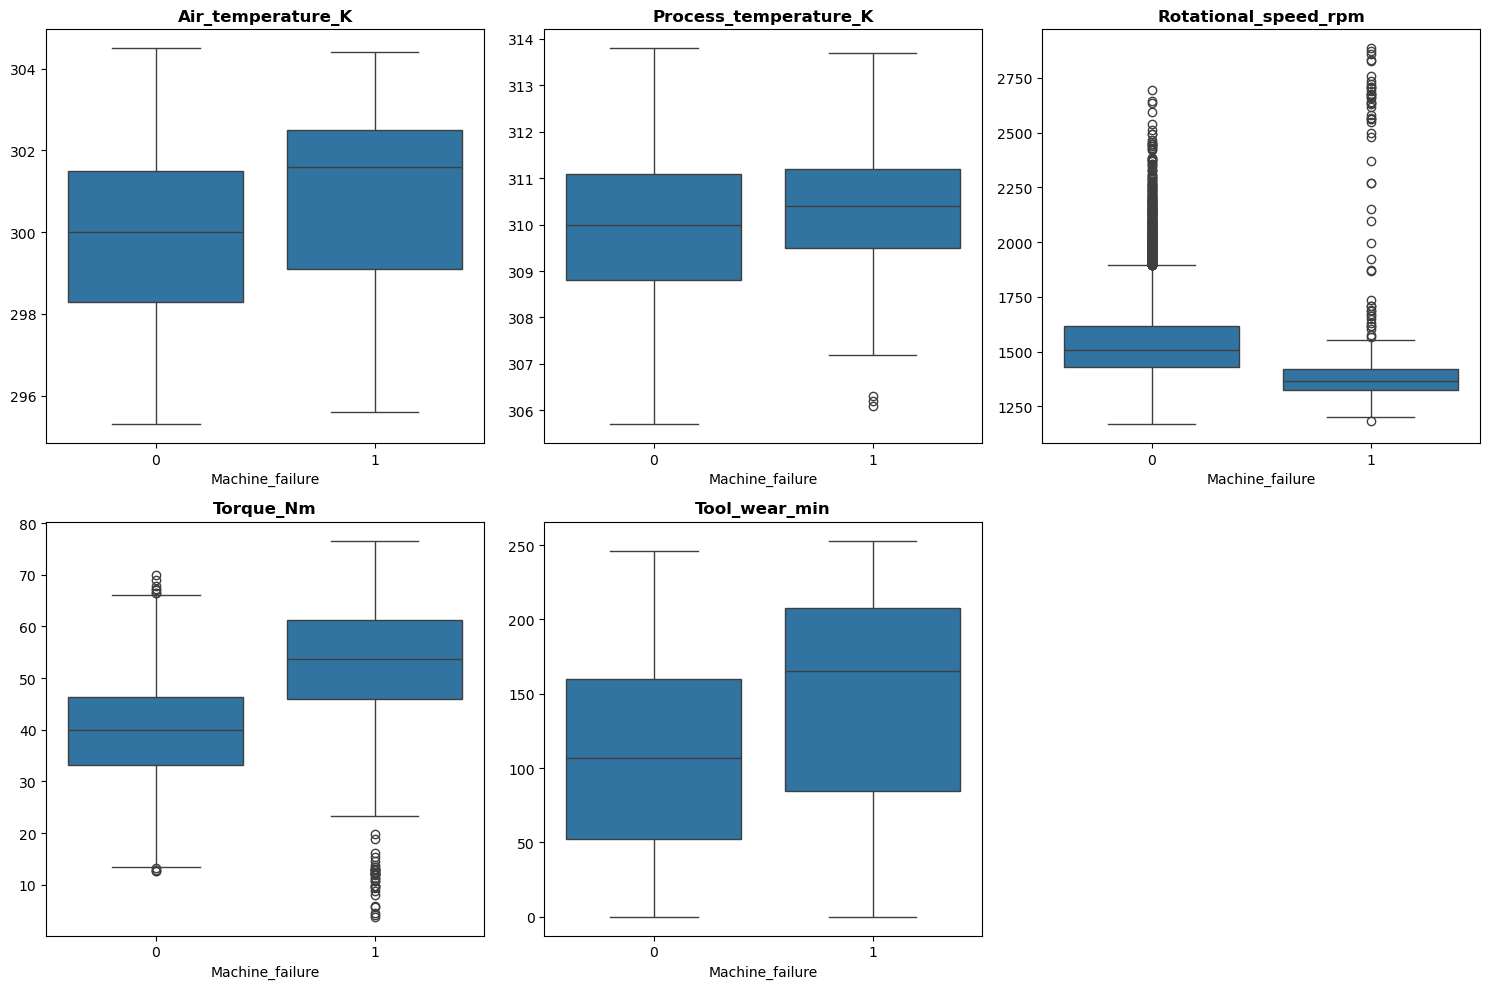

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(variables_fisicas):
    sns.boxplot(
        data=df, 
        x='Machine_failure', 
        y=col, 
        ax=axes[i]
    )

    axes[i].set_title(col, fontweight='bold')
    axes[i].set_ylabel('')

axes[5].axis('off')

plt.tight_layout()
plt.show()

Observamos tanto en los histogramas como en los boxplot, que la distribución de variables es distinta en los casos que falló la máquina. Se observa una temperatura más alta, al igual que un torque y un tiempo de uso de herramienta mayor, a su vez que la velocidad rotacional disminuye significativamente. Esta variación en las distribuciones serán las que nos servirán para entrenar a nuestro modelo predictivo


4. Análisis de la variable categórica Type

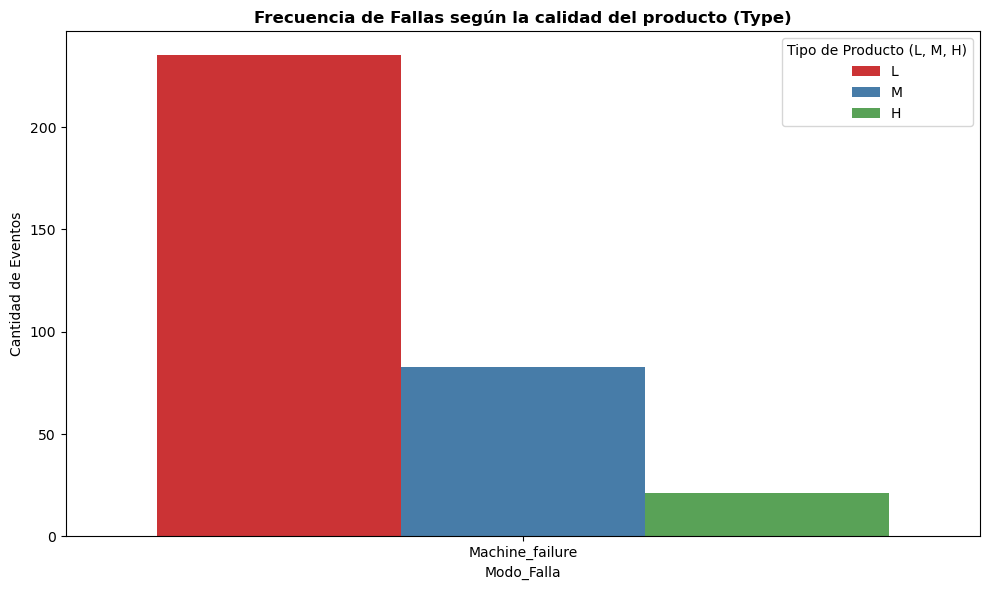

In [20]:
fallas_melt = df.melt(id_vars=['Type'],
                      value_vars=['Machine_failure'],
                      var_name='Modo_Falla',
                      value_name='Ocurrencia')

fallas_positivas = fallas_melt[fallas_melt['Ocurrencia'] == 1]

plt.figure(figsize=(10,6))
sns.countplot(
    data=fallas_positivas,
    x='Modo_Falla',
    hue='Type',
    palette='Set1',
)

plt.title('Frecuencia de Fallas según la calidad del producto (Type)', fontweight='bold')
plt.ylabel('Cantidad de Eventos')
plt.legend(title='Tipo de Producto (L, M, H)')
plt.tight_layout()
plt.show()

## 1.5 Análisis de normalidad de las variables operativas ##

### 1.5.1 Prueba Shapiro-Wilk ###

La evaluación de las distribuciones constituye una etapa importante del análisis exploratorio, ya que permite comprender el comportamiento estadístico de las variables físicas.

Para complementar los histogramas, utilizaremos la prueba de Shapiro-Wilk, cuya hipótesis nula establece que los datos provienen de una distribución normal.

Se trabajará con un nivel de significancia de 0,05:

- Si **p < 0,05**, rechazamos la hipótesis nula y encontramos evidencia estadística contra la normalidad.
- Si **p ≥ 0,05**, no encontramos evidencia suficiente para rechazar la hipótesis nula. Esto no significa que hayamos demostrado que la distribución es normal.

Como el tamaño de muestra puede influir en las pruebas estadísticas, complementaremos los resultados con gráficos Q-Q.

El objetivo no es transformar automáticamente todas las variables a una distribución normal, sino comprender sus características y determinar si alguna transformación podría resultar útil para los análisis posteriores.

In [21]:
from scipy.stats import shapiro
import pandas as pd

variables_fisicas = [
    "Air_temperature_K",
    "Process_temperature_K",
    "Rotational_speed_rpm",
    "Torque_Nm",
    "Tool_wear_min"
]

resultados_normalidad = []

for variable in variables_fisicas:

    # Muestra reproducible de 5.000 observaciones
    muestra = df[variable].dropna().sample(
        n=min(5000, df[variable].notna().sum()),
        random_state=42
    )

    estadistico, p_valor = shapiro(muestra)

    resultados_normalidad.append({
        "Variable": variable,
        "Estadístico W": estadistico,
        "p-valor": p_valor,
        "Interpretación": (
            "Se rechaza normalidad"
            if p_valor < 0.05
            else "No se rechaza normalidad"
        )
    })

tabla_normalidad = pd.DataFrame(resultados_normalidad)

display(tabla_normalidad)

,Variable,Estadístico W,p-valor,Interpretación
0,Air_temperature_K,0.978699,9.584391e-27,Se rechaza normalidad
1,Process_temperature_K,0.991491,9.095543e-17,Se rechaza normalidad
2,Rotational_speed_rpm,0.859811,4.592873e-55,Se rechaza normalidad
3,Torque_Nm,0.999558,3.179779e-01,No se rechaza normalidad
4,Tool_wear_min,0.957451,6.435775e-36,Se rechaza normalidad


*Nota*: Usamos una muestra de 5.000 observacionees porque SciPy advierte que para muestras mayores a este tamaño el valor p de Shapiro-Wilk puede no ser preciso. Utilizamos una muestra aleatoria.

### Conclusiones del análisis de normalidad

Se aplicó la prueba de Shapiro-Wilk a una muestra aleatoria reproducible de 5.000 observaciones por variable, utilizando un nivel de significancia de 0,05.

Los resultados indican que cuatro de las cinco variables operativas presentan evidencia estadística suficiente para rechazar la hipótesis de normalidad: temperatura del aire, temperatura del proceso, velocidad de rotación y desgaste de herramienta.

La variable `Torque_Nm`, en cambio, obtuvo un p-valor aproximado de 0,318, por lo que no se rechaza la hipótesis de normalidad. Esto no demuestra que su distribución sea perfectamente normal, sino que la prueba no encontró evidencia suficiente para descartarla.

Entre las variables analizadas, la velocidad de rotación presentó el estadístico W más alejado de 1, lo que indica una mayor discrepancia respecto de la distribución normal en la muestra utilizada.


### 1.5.2 Gráficos Q-Q ###

Para complementar los resultados de la prueba de Shapiro-Wilk, vamos a usar gráficos cuantíl-cuantíl (Q-Q), que permiten comparar los cuantiles observados de cada variable con los cuantiles teóricos de una distribución normal.

Si los puntos se aproximan a la línea de referencia, existe una mayor semejanza con la distribución normal. Las desviaciones sistemáticas respecto de la línea pueden indicar asimetría, diferencias en las colas u otros patrones no normales.

Este análisis visual complementa los resultados estadísticos y permite comprender mejor la distribución de las variables operativas antes de continuar con las correlaciones y el modelado.

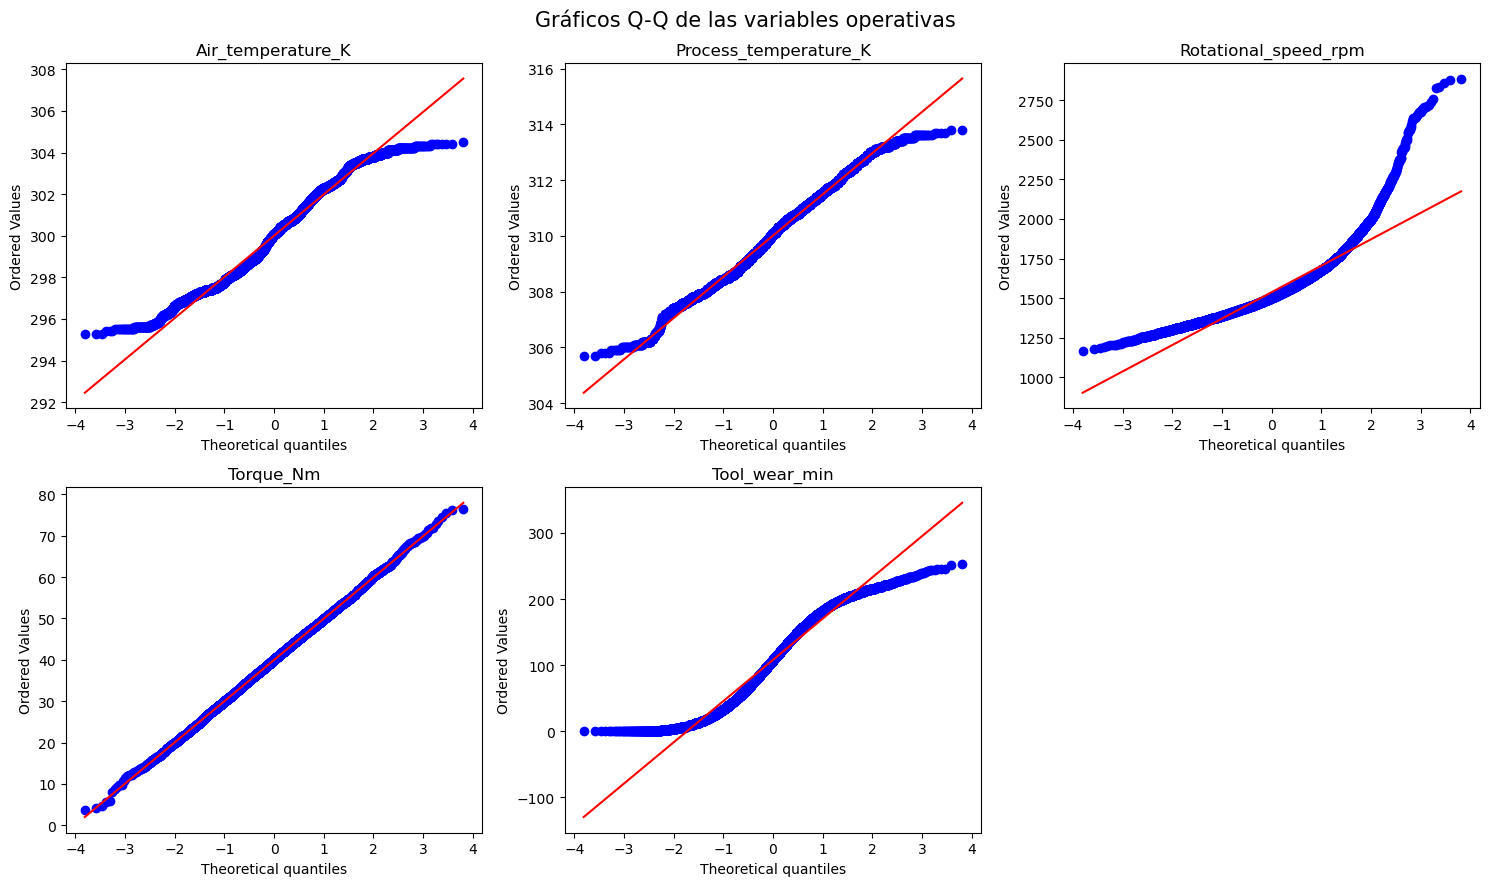

In [22]:
import matplotlib.pyplot as plt
from scipy import stats

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, variable in enumerate(variables_fisicas):
    stats.probplot(
        df[variable].dropna(),
        dist="norm",
        plot=axes[i]
    )
    axes[i].set_title(variable)

# Eliminar el gráfico vacío
fig.delaxes(axes[-1])

plt.suptitle(
    "Gráficos Q-Q de las variables operativas",
    fontsize=15
)

plt.tight_layout()
plt.show()

### Conclusiones del análisis de normalidad ###

El análisis de normalidad se realizó mediante la prueba estadística de Shapiro-Wilk y gráficos cuantíl-cuantíl (Q-Q), utilizando ambas herramientas de manera complementaria.

Los resultados de Shapiro-Wilk, aplicados sobre muestras aleatorias reproducibles de 5.000 observaciones, mostraron evidencia estadística suficiente para rechazar la hipótesis de normalidad en cuatro de las cinco variables operativas: temperatura del aire, temperatura del proceso, velocidad de rotación y desgaste de herramienta.

La única variable para la cual no se rechazó la hipótesis de normalidad fue `Torque_Nm` (p ≈ 0,318).

Los gráficos Q-Q permitieron profundizar esta interpretación:

- **Temperaturas:** presentan una aproximación a la distribución normal en la región central, pero muestran desviaciones en los extremos.
- **Velocidad de rotación:** evidencia una marcada asimetría positiva, con una cola derecha considerablemente extendida.
- **Torque:** presenta una alineación prácticamente lineal respecto de los cuantiles normales teóricos.
- **Desgaste de herramienta:** exhibe una forma de S, con desviaciones sistemáticas respecto de la distribución normal.

Estos resultados permiten comprender mejor las características estadísticas de las variables físicas.

**Implicancias para el modelado:** no se considera necesario transformar automáticamente las variables para aproximarlas a una distribución normal. Los algoritmos Random Forest y XGBoost no requieren normalidad en los predictores y, en el caso de la regresión logística, tampoco es un supuesto obligatorio.

Por lo tanto, cualquier transformación adicional será evaluada posteriormente según su aporte al desempeño del modelo y no únicamente por su capacidad para modificar la forma de las distribuciones.

## 1.6 Análisis de relaciones ##

El análisis de correlaciones nos permite estudiar la dirección y la intensidad de las asociaciones entre las variables operativas del dataset.

Para obtener una interpretación más completa, se compararán tres coeficientes:

- **Pearson:** mide la intensidad y dirección de las relaciones lineales entre variables numéricas.
- **Spearman:** evalúa relaciones monotónicas mediante los rangos de las observaciones.
- **Kendall:** mide la concordancia entre pares de observaciones y permite estudiar asociaciones basadas en rangos.

La comparación es relevante porque las variables operativas pueden presentar relaciones que no sean estrictamente lineales, como ocurre potencialmente entre el torque y la velocidad de rotación.

También se analizarán las asociaciones entre las características originales y las variables derivadas de principios físicos, como la diferencia de temperaturas y la potencia mecánica aproximada.

Es importante recordar que una correlación elevada no demuestra causalidad ni garantiza una mejora en la capacidad predictiva del modelo.

In [23]:
# Copia para el análisis exploratorio de relaciones físicas
df_analisis = df.copy()

# Diferencia entre temperatura de proceso y temperatura del aire
df_analisis["Temperature_difference_K"] = (
    df_analisis["Process_temperature_K"]
    - df_analisis["Air_temperature_K"]
)

# Velocidad angular en rad/s
df_analisis["Angular_speed_rad_s"] = (
    2 * np.pi * df_analisis["Rotational_speed_rpm"] / 60
)

# Potencia mecánica aproximada en watts
df_analisis["Mechanical_power_W"] = (
    df_analisis["Torque_Nm"]
    * df_analisis["Angular_speed_rad_s"]
)

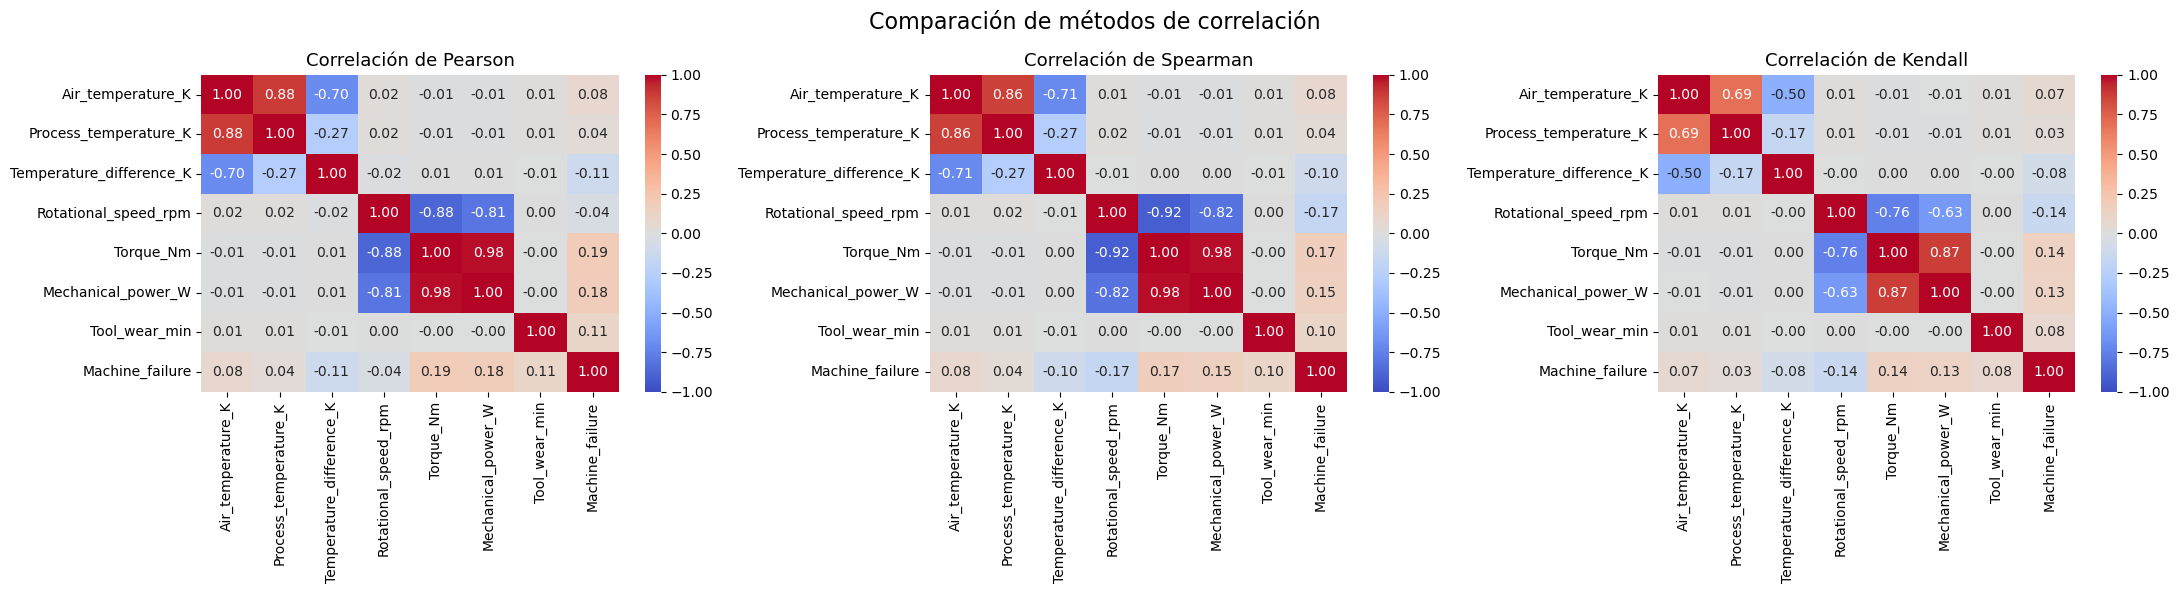

In [24]:
# Selección de variables para el análisis de correlaciones
columnas_correlacion = [
    "Air_temperature_K",
    "Process_temperature_K",
    "Temperature_difference_K",
    "Rotational_speed_rpm",
    "Torque_Nm",
    "Mechanical_power_W",
    "Tool_wear_min",
    'Machine_failure'
]

df_num = df_analisis[columnas_correlacion].copy()

# Métodos de correlación
metodos = ["pearson", "spearman", "kendall"]

fig, axes = plt.subplots(1, 3, figsize=(22, 6))

for ax, metodo in zip(axes, metodos):

    matriz_corr = df_num.corr(method=metodo)

    sns.heatmap(
        matriz_corr,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        center=0,
        ax=ax
    )

    ax.set_title(
        f"Correlación de {metodo.capitalize()}",
        fontsize=13
    )

plt.suptitle(
    "Comparación de métodos de correlación",
    fontsize=16
)

plt.tight_layout()
plt.show()

### Conclusiones del análisis de correlaciones

Se calcularon las matrices de correlación de Pearson, Spearman y Kendall para estudiar las asociaciones entre las variables operativas originales y las características derivadas.

Los resultados permitieron identificar relaciones relevantes:

- **Temperatura del aire y temperatura del proceso:** presentan una fuerte asociación positiva (Pearson = 0,88), indicando que ambas variables tienden a variar en la misma dirección.
- **Velocidad de rotación y torque:** muestran una asociación negativa elevada (Pearson = -0,88; Spearman = -0,92). Esto sugiere una relación inversa importante entre ambas condiciones operativas.
- **Torque y potencia mecánica:** presentan una correlación positiva muy elevada (Pearson = 0,98), lo que evidencia una posible redundancia de información entre estas características.
- **Desgaste de herramienta:** presenta correlaciones próximas a cero con las demás variables, lo que indica ausencia de asociaciones lineales.

La comparación entre Pearson, Spearman y Kendall muestra que las principales asociaciones mantienen su dirección, aunque varían en magnitud según el coeficiente utilizado.

**Implicancias para el modelado:** las correlaciones elevadas sugieren que algunas variables podrían contener información parcialmente redundante. Esto deberá considerarse especialmente al interpretar los coeficientes de regresión logística, aunque no implica que debamos eliminar automáticamente variables.

Por otra parte, las variables derivadas, como la diferencia de temperaturas y la potencia mecánica, podrían aportar información relevante sobre las condiciones operativas. Su utilidad será evaluada posteriormente mediante experimentos comparativos de desempeño.

Finalmente, es importante destacar que la correlación no implica causalidad y que una correlación baja entre dos variables no descarta relaciones no lineales, interacciones o capacidad predictiva respecto de la variable objetivo.

## 1.7 Ingeniería de características e hipótesis físicas ##

Las fallas de maquinaria industrial pueden estar asociadas con la interacción entre diferentes condiciones operativas. Por este motivo, resulta relevante estudiar combinaciones de variables que permitan identificar patrones que no necesariamente se observan al analizar cada característica de manera individual.

En esta sección aplicaremos técnicas de **ingeniería de características (*Feature Engineering*)**, construyendo nuevas variables a partir de las mediciones originales del dataset y explorando sus relaciones con la presencia de fallas.

### Hipótesis exploratorias

Planteamos las siguientes hipótesis:

1. **Diferencia de temperaturas:** investigar si la diferencia entre la temperatura del proceso y la temperatura del aire presenta comportamientos distintos en los registros con y sin falla.
2. **Torque y velocidad de rotación:** estudiar si determinadas combinaciones de carga mecánica y velocidad de funcionamiento se asocian con una mayor presencia de fallas.
3. **Desgaste de herramienta y torque:** explorar si la combinación de desgaste y esfuerzo mecánico permite identificar condiciones operativas particulares.
4. **Interacciones entre variables:** investigar si las fallas se concentran en determinadas regiones del espacio de características.

Estas hipótesis se explorarán mediante visualizaciones multivariables y posteriormente mediante análisis cuantitativos, sin asumir relaciones causales.

### Construcción de características derivadas

Para profundizar el análisis se construirán las siguientes variables:

- **Diferencia de temperaturas $(\Delta T)$ :** diferencia entre la temperatura del proceso y la temperatura del aire.
- **Velocidad angular $(\omega)$ :** conversión de la velocidad de rotación de rpm a rad/s.
- **Potencia mecánica rotacional aproximada $(P)$ :** variable calculada a partir del torque y la velocidad angular.

La potencia mecánica rotacional se expresa como:

$$
P = \tau \omega = \tau \frac{2\pi n}{60}
$$

Donde:

- $\tau$ : torque, expresado en N·m.
- $\omega$ : velocidad angular, expresada en rad/s.
- $n$ : velocidad de rotación, expresada en rpm.
- $P$ : potencia mecánica rotacional aproximada, expresada en watts (W).

Estas características permiten representar diferentes aspectos físicos de la operación. Sin embargo, su utilidad predictiva no puede determinarse únicamente a partir de las visualizaciones o correlaciones, por lo que posteriormente se evaluará su contribución al desempeño de los modelos mediante experimentos comparativos.

In [25]:
display(
    df_analisis[
        [
            "Air_temperature_K",
            "Process_temperature_K",
            "Temperature_difference_K",
            "Rotational_speed_rpm",
            "Torque_Nm",
            "Mechanical_power_W",
            "Tool_wear_min",
            "Machine_failure"
        ]
    ].head()
)


,Air_temperature_K,Process_temperature_K,Temperature_difference_K,Rotational_speed_rpm,Torque_Nm,Mechanical_power_W,Tool_wear_min,Machine_failure
0,298.1,308.6,10.5,1551,42.8,6951.590560,0,0
1,298.2,308.7,10.5,1408,46.3,6826.722724,3,0
2,298.1,308.5,10.4,1498,49.4,7749.387543,5,0
3,298.2,308.6,10.4,1433,39.5,5927.504659,7,0
4,298.2,308.7,10.5,1408,40.0,5897.816608,9,0


### 1.7.1 Relación entre torque, velocidad y desgaste ###

Para investigar las condiciones mecánicas asociadas a las fallas, analizaremos conjuntamente la velocidad de rotación, el torque y el desgaste de herramienta.

En el gráfico de dispersión, la velocidad se representa en el eje horizontal, el torque en el eje vertical y el desgaste mediante el tamaño de los puntos. El color permite diferenciar los registros con falla de aquellos que no presentan fallas.

Esta visualización busca identificar regiones de funcionamiento en las que aparecen fallas y explorar si existen patrones que no resultan evidentes al analizar cada variable individualmente.

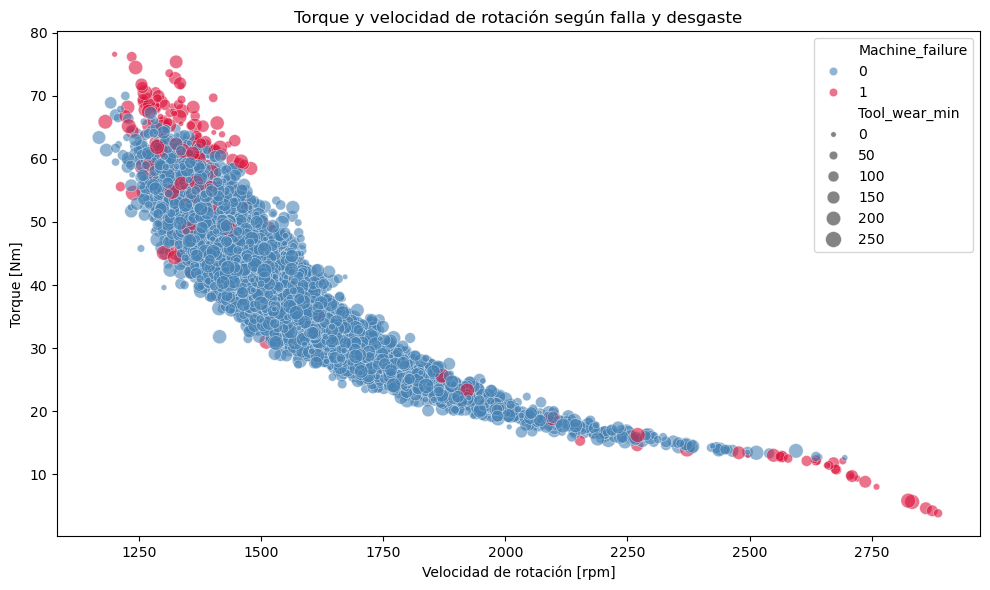

In [26]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_analisis,
    x="Rotational_speed_rpm",
    y="Torque_Nm",
    hue="Machine_failure",
    size="Tool_wear_min",
    sizes=(15, 130),
    palette={0: "steelblue", 1: "crimson"},
    alpha=0.6,
    legend="brief"
)

plt.title("Torque y velocidad de rotación según falla y desgaste")
plt.xlabel("Velocidad de rotación [rpm]")
plt.ylabel("Torque [Nm]")
plt.tight_layout()
plt.show()

**Interpretación del gráfico**

Se observa una fuerte relación inversa y curvilínea entre la velocidad de rotación y el torque. Las fallas aparecen visualmente en mayor medida en determinadas regiones extremas, particularmente en condiciones de torque elevado y baja velocidad, así como en velocidades muy altas con torque reducido.

En la región central predominan los registros sin falla, aunque también existen observaciones con fallas.

El desgaste de herramienta está representado mediante el tamaño de los puntos, pero la superposición de observaciones dificulta determinar visualmente su influencia.

Estos resultados sugieren que ciertas combinaciones de variables mecánicas podrían estar asociadas a las fallas. Sin embargo, será necesario complementar el análisis con tasas de falla por región para cuantificar estas diferencias.

### 1.7.2 Diferencia térmica y velocidad de rotación ###

Para complementar el análisis de las condiciones mecánicas, vamos a estudiar la relación entre la diferencia de temperaturas y la velocidad de rotación.

La diferencia térmica (Temperature_difference_K) se calcula restando la temperatura del aire a la temperatura del proceso. Esta variable permite analizar el comportamiento térmico de la máquina desde una perspectiva diferente a la que ofrecen ambas temperaturas por separado.

Mediante un gráfico de dispersión, representamos la diferencia térmica en el eje horizontal y la velocidad de rotación en el eje vertical, utilizando colores para distinguir los registros con falla de aquellos que no presentan fallas.

El objetivo es explorar si determinadas combinaciones de condiciones térmicas y velocidades de funcionamiento presentan patrones asociados con la aparición de fallas.

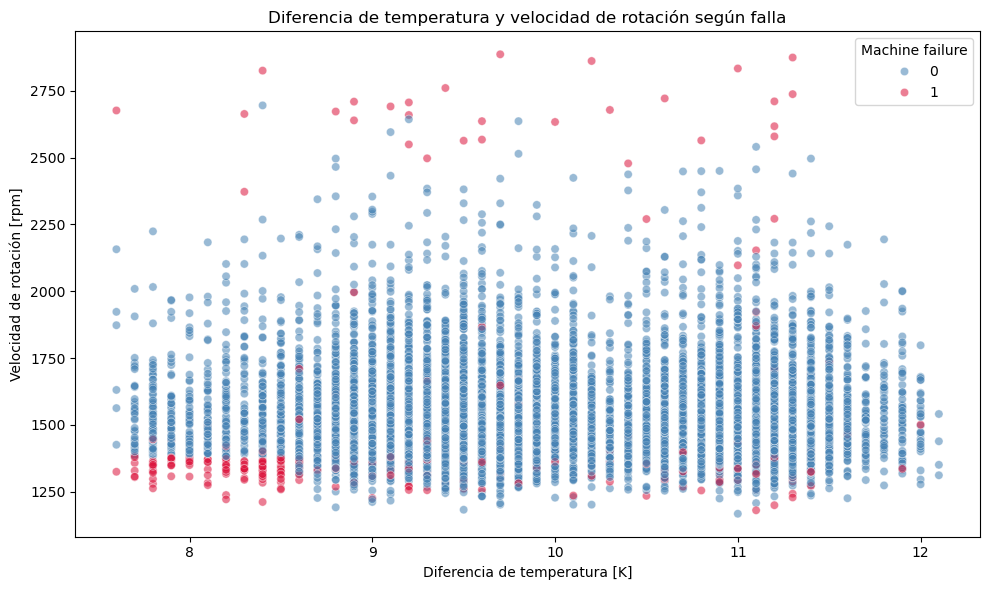

In [27]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_analisis,
    x="Temperature_difference_K",
    y="Rotational_speed_rpm",
    hue="Machine_failure",
    palette={0: "steelblue", 1: "crimson"},
    alpha=0.55
)

plt.title("Diferencia de temperatura y velocidad de rotación según falla")
plt.xlabel("Diferencia de temperatura [K]")
plt.ylabel("Velocidad de rotación [rpm]")
plt.legend(title="Machine failure")
plt.tight_layout()
plt.show()

**Interpretación del gráfico**

Se observa que los registros con falla aparecen en diferentes valores de diferencia térmica, sin una separación visual clara respecto de los registros sin falla basada únicamente en esta característica.

Sin embargo, se identifican observaciones con falla en condiciones de velocidad de rotación especialmente bajas o elevadas.

Esto sugiere que la velocidad podría estar asociada con determinadas condiciones de falla y que el comportamiento de la diferencia térmica debería analizarse conjuntamente con otras variables operativas.

Si bien el gráfico permite identificar patrones exploratorios, no es suficiente para establecer relaciones causales ni demostrar la capacidad predictiva de las características analizadas.

### 1.7.3 Tasas de fallas según condiciones operativas ###

En los gráficos anteriores identificamos visualmente que algunas fallas aparecen en condiciones extremas de torque y velocidad de rotación.

Sin embargo, debido al desbalance de clases del dataset, la cantidad absoluta de observaciones con falla no permite determinar por sí sola qué condiciones presentan mayor riesgo relativo.

Para profundizar el análisis, dividiremos el torque y la velocidad de rotación en intervalos y calcularemos el porcentaje de registros con Machine_failure = 1 dentro de cada combinación.

Los resultados se visualizarán mediante un mapa de calor, que permitirá comparar la frecuencia relativa de fallas entre distintas regiones operativas.

También consideraremos la cantidad de observaciones en cada intervalo, dado que los porcentajes calculados sobre grupos muy pequeños pueden resultar poco representativos.

Este procedimiento constituye un análisis exploratorio de asociaciones y no debe interpretarse como una estimación causal ni como una probabilidad validada de falla futura.

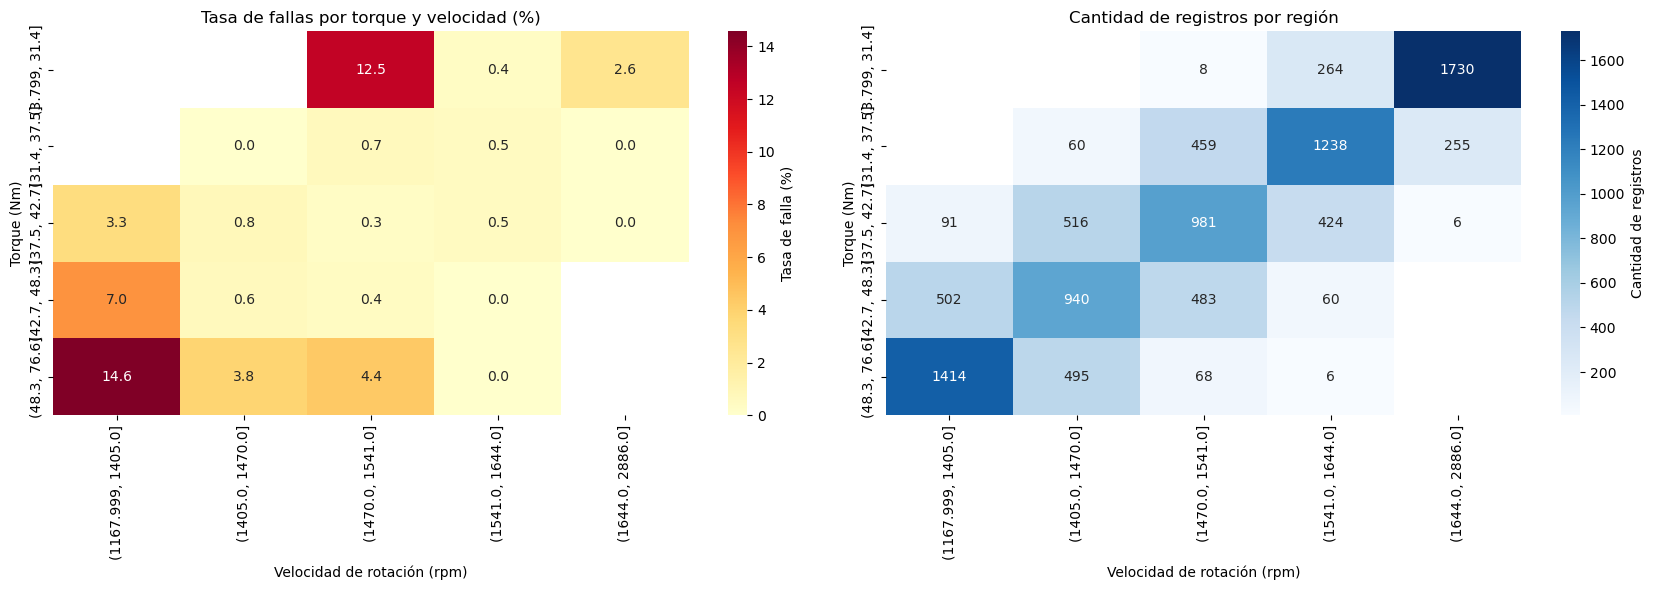

In [28]:
# 1.7.3 - Tasa de fallas según torque y velocidad

df_tasas = df_analisis.copy()

# Crear cinco intervalos por variable
df_tasas["Rango_velocidad"] = pd.qcut(
    df_tasas["Rotational_speed_rpm"],
    q=5,
    duplicates="drop"
)

df_tasas["Rango_torque"] = pd.qcut(
    df_tasas["Torque_Nm"],
    q=5,
    duplicates="drop"
)

# Calcular tasa de fallas por combinación
resumen_tasas = (
    df_tasas
    .groupby(
        ["Rango_torque", "Rango_velocidad"],
        observed=True
    )["Machine_failure"]
    .agg(
        cantidad="count",
        fallas="sum",
        tasa="mean"
    )
    .reset_index()
)

resumen_tasas["Tasa_falla_pct"] = (
    resumen_tasas["tasa"] * 100
)

# Crear matrices para los mapas de calor
matriz_tasas = resumen_tasas.pivot(
    index="Rango_torque",
    columns="Rango_velocidad",
    values="Tasa_falla_pct"
)

matriz_cantidad = resumen_tasas.pivot(
    index="Rango_torque",
    columns="Rango_velocidad",
    values="cantidad"
)

# Visualización
fig, axes = plt.subplots(1, 2, figsize=(17, 6))

sns.heatmap(
    matriz_tasas,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    cbar_kws={"label": "Tasa de falla (%)"},
    ax=axes[0]
)

axes[0].set_title("Tasa de fallas por torque y velocidad (%)")
axes[0].set_xlabel("Velocidad de rotación (rpm)")
axes[0].set_ylabel("Torque (Nm)")

sns.heatmap(
    matriz_cantidad,
    annot=True,
    fmt=".0f",
    cmap="Blues",
    cbar_kws={"label": "Cantidad de registros"},
    ax=axes[1]
)

axes[1].set_title("Cantidad de registros por región")
axes[1].set_xlabel("Velocidad de rotación (rpm)")
axes[1].set_ylabel("Torque (Nm)")

plt.tight_layout()
plt.show()

**Interpretación de los resultados**

El análisis de las tasas de falla por intervalos de torque y velocidad de rotación permitió cuantificar algunos de los patrones identificados previamente en los gráficos de dispersión.

La combinación de torque elevado (aproximadamente entre 48,3 y 76,6 Nm) y velocidad reducida (hasta 1405 rpm) presentó una tasa de falla del **14,6 % sobre 1.414 registros**, considerablemente superior a la tasa general del dataset (3,39 %).

Esta diferencia sugiere que determinadas combinaciones de condiciones mecánicas están asociadas con una mayor frecuencia relativa de fallas.

Asimismo, se identificaron otras regiones con tasas elevadas, aunque algunas contienen muy pocas observaciones. Por ejemplo, una región presentó una tasa del 12,5 % sobre solamente ocho registros, por lo que su resultado debe interpretarse con precaución.

Los mapas también muestran que determinadas combinaciones de torque y velocidad tienen escasa representación debido a la fuerte relación inversa existente entre ambas variables.

**Implicancias para el modelado:** estos resultados respaldan la hipótesis de que las interacciones entre variables mecánicas pueden aportar información relevante para la clasificación de fallas.

Sin embargo, las tasas observadas representan asociaciones descriptivas del dataset, no probabilidades de falla futura validadas ni relaciones causales.

La utilidad predictiva de estas interacciones deberá comprobarse posteriormente mediante entrenamiento y evaluación de modelos sobre datos independientes.

### 1.7.4. Conclusiones generales de ingeniería de características

El análisis de relaciones físicas permitió identificar patrones relevantes entre las condiciones operativas y la presencia de fallas en el dataset.

A partir de las variables originales se construyeron tres características derivadas: diferencia de temperaturas, velocidad angular y potencia mecánica rotacional aproximada. Estas variables permiten representar relaciones físicas que no quedan expresadas directamente mediante las mediciones individuales.

**Principales hallazgos:**

1. **Relación entre torque y velocidad:** se identificó una fuerte asociación inversa y no lineal entre ambas variables (Pearson = -0,88; Spearman = -0,92).

2. **Condiciones mecánicas asociadas a fallas:** las combinaciones de torque elevado (48,3–76,6 Nm) y velocidad reducida (hasta 1405 rpm) presentaron una tasa de falla del 14,6 % sobre 1.414 registros, frente al 3,39 % general del dataset.

3. **Comportamiento térmico:** la diferencia de temperaturas no mostró una separación visual clara entre registros con y sin falla al analizarse conjuntamente con la velocidad. Sin embargo, no se descarta que pueda aportar información mediante interacciones con otras características.

4. **Posible redundancia entre variables:** la potencia mecánica presentó una correlación elevada con el torque (Pearson = 0,98). Esto sugiere información parcialmente redundante, aunque no demuestra que la variable derivada carezca de utilidad predictiva.

5. **Desgaste de herramienta:** su influencia no pudo determinarse claramente mediante los gráficos de dispersión debido a la superposición de observaciones. Será necesario evaluar su contribución durante el modelado.

**Implicancias para el entrenamiento de Machine Learning**

Los resultados respaldan la importancia de analizar las condiciones operativas de forma conjunta, especialmente las interacciones entre torque y velocidad de rotación.

En consecuencia, se conservarán inicialmente las características derivadas como candidatas para el entrenamiento de los modelos.

Para comprobar su utilidad, se realizará posteriormente un **estudio de ablación de características**, comparando modelos entrenados con las variables originales frente a modelos que también incorporen las variables derivadas.

Esta evaluación permitirá determinar si la ingeniería de características mejora efectivamente la detección de fallas y contribuye a reducir las falsas alarmas.

Finalmente, los patrones identificados corresponden a asociaciones observadas en un dataset sintético y no permiten establecer relaciones causales ni garantizar su generalización a maquinaria industrial real.

In [30]:
# Eliminamos columnas que generarían Target Leakage (filtración de datos)
# No podemos predecir si la máquina falló usando los sensores de falla que se activan durante el fallo.
df_final = df_analisis.drop(columns=['TWF', 'HDF', 'PWF', 'OSF', 'RNF'])

# Exportamos a CSV para el notebook de Machine Learning
df_final.to_csv('Material/Datasets/ai4i2020_model_ready.csv', index=False)
print("Dataset exportado exitosamente para modelado.")

Dataset exportado exitosamente para modelado.
